# Lesson 8 · The EDA Playbook: Exploring Any Unfamiliar Dataset
### A repeatable routine from 'what is this?' to 'here is what a model could learn from it'

| | |
|---|---|
| **Type** | SOLUTIONS 08 |
| **Time** | about 180 minutes |
| **Level** | Intermediate |
| **Prerequisites** | Lessons 1–7 |

**By the end of this notebook you will be able to:**

- Run an 8-step EDA routine on a dataset you have never seen
- Describe distributions, skew and outliers, and tell an *error* from a *legitimate extreme*
- Find relationships between numeric, categorical and mixed variables
- Detect confounding by stratifying, and avoid mistaking correlation for causation
- Identify trends, seasonality and autocorrelation in a time series
- Turn observations into testable **hypotheses**, and produce an **ML-readiness** assessment

## 🛠️ Setup (identical to the lesson notebook)

In [1]:

import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from course_utils import DATA_DIR, check, check_plot, first_look

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 100})
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 140)

dairy = pd.read_csv(DATA_DIR / "dairy_farms.csv")        # NEW, unfamiliar data: a survey of 1,200 dairy farms
prices = pd.read_csv(DATA_DIR / "market_prices_clean.csv", parse_dates=["date"])
print("Setup complete ✔  dairy", dairy.shape, "| prices", prices.shape)


Setup complete ✔  dairy (1200, 15) | prices (15048, 9)


### 🧩 Problem 8.1: Which variable is most skewed?

Among `herd_size`, `farm_acres`, `vet_visits_per_year`, `farmer_age` in the raw `dairy` table, which has the **largest (positive) skewness**?

*Expected type:* a string (column name).

In [2]:
answer = dairy[["herd_size", "farm_acres", "vet_visits_per_year", "farmer_age"]].skew().idxmax()

check('08-p1', answer)

✅ 08-p1: correct! Nicely done.


True

### 🧩 Problem 8.2: Herd-size outliers by the IQR rule

Using the **IQR rule** (below `Q1 − 1.5·IQR` or above `Q3 + 1.5·IQR`, quartiles via `quantile`) on `dairy['herd_size']`, how many farms are flagged?

*Expected type:* integer.

In [3]:
s = dairy["herd_size"]
q1, q3 = s.quantile([0.25, 0.75])
iqr = q3 - q1
answer = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

check('08-p2', answer)

✅ 08-p2: correct! Nicely done.


True

### 🧩 Problem 8.3: Rows that break the arithmetic

In the raw `dairy` table, `milk_per_cow_l_day × lactating_cows` should (approximately) equal `total_milk_l_day`. Count the rows where the **relative difference** `|implied − total| / total` exceeds **0.10**.

*Expected type:* integer.

In [4]:
implied = dairy["milk_per_cow_l_day"] * dairy["lactating_cows"]
gap = (implied - dairy["total_milk_l_day"]).abs() / dairy["total_milk_l_day"]
answer = int((gap > 0.10).sum())

check('08-p3', answer)

✅ 08-p3: correct! Nicely done.


True

### 🧩 Problem 8.4: Yield by feed system (excluding impossible values)

Drop rows from raw `dairy` where `milk_per_cow_l_day` is **greater than 40** (impossible values). Then return the **mean `milk_per_cow_l_day` for each `feed_system`** as a dictionary, rounded to 2 decimals.

*Expected type:* dict.

In [5]:
ok = dairy[dairy["milk_per_cow_l_day"] <= 40]
answer = ok.groupby("feed_system")["milk_per_cow_l_day"].mean().round(2).to_dict()

check('08-p4', answer)

✅ 08-p4: correct! Nicely done.


True

### 🧩 Problem 8.5: Spearman: herd size and revenue

What is the **Spearman** rank correlation between `herd_size` and `monthly_revenue_kes` in raw `dairy`? Round to 3 decimals.

*Expected type:* float.

In [6]:
answer = round(float(dairy["herd_size"].corr(dairy["monthly_revenue_kes"], method="spearman")), 3)

check('08-p5', answer)

✅ 08-p5: correct! Nicely done.


True

### 🧩 Problem 8.6: The cooling effect, controlling for county

Compute, **within each county**, the difference in mean `price_kes_per_litre` between farms **with** (`has_cooling == 1`) and **without** (`== 0`) a cooling tank (ignore missing prices). Return the **simple average of these county gaps**, rounded to 2 decimals.

*Expected type:* float.

In [7]:
t = dairy.groupby(["county", "has_cooling"])["price_kes_per_litre"].mean().unstack()
answer = round(float((t[1] - t[0]).mean()), 2)

check('08-p6', answer)

✅ 08-p6: correct! Nicely done.


True

### 🧩 Problem 8.7: Year-on-year maize inflation

Compute the **national mean maize price** per calendar year (mean of all maize rows in `prices`). Return the **percentage change from 2022 to 2023**, rounded to 1 decimal.

*Expected type:* float.

In [8]:
y = prices[prices["crop"] == "Maize"].groupby(prices["date"].dt.year)["price_kes_per_kg"].mean()
answer = round(float((y[2023] / y[2022] - 1) * 100), 1)

check('08-p7', answer)

✅ 08-p7: correct! Nicely done.


True

### 🎨 Problem 8.8: Feed system and yield - a chart for the co-op

Using the raw `dairy` data **excluding** `milk_per_cow_l_day > 40`, draw a **box plot** of `milk_per_cow_l_day` for each `feed_system` (Seaborn). Title and axis labels with units are required.

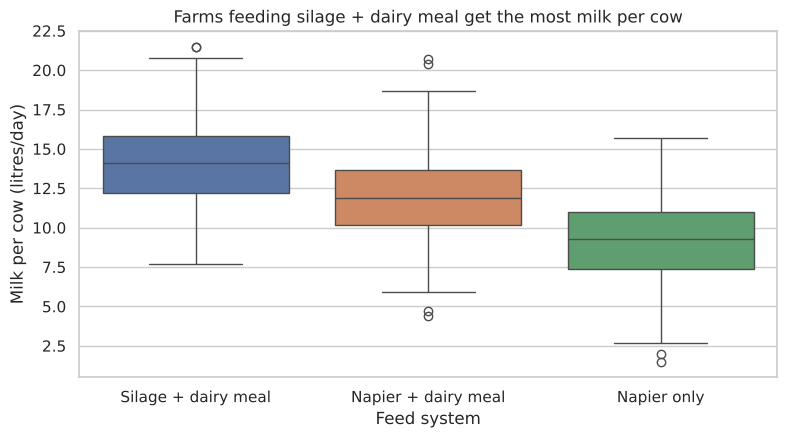

✅ 08-p8: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?

True

In [9]:
ok = dairy[dairy["milk_per_cow_l_day"] <= 40]
fig, ax = plt.subplots()
sns.boxplot(data=ok, x="feed_system", y="milk_per_cow_l_day", hue="feed_system", legend=False, ax=ax)
ax.set_title("Farms feeding silage + dairy meal get the most milk per cow")
ax.set_xlabel("Feed system"); ax.set_ylabel("Milk per cow (litres/day)")
plt.show()

check_plot(ax, min_lines=9, name='08-p8')

### 🎨 Problem 8.9: Revenue vs herd size on a log–log scale

Draw a **scatter plot** of `herd_size` (x) against `monthly_revenue_kes` (y) for raw `dairy`, with **both axes on a log scale**, `alpha=0.4`, a title and axis labels.

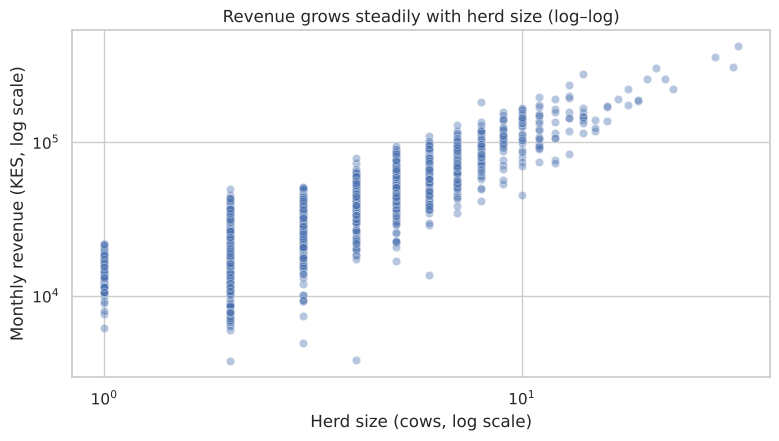

✅ 08-p9: your chart has the essentials. Now ask yourself: would a stranger understand it in 10 seconds?


True

In [10]:
fig, ax = plt.subplots()
sns.scatterplot(data=dairy, x="herd_size", y="monthly_revenue_kes", alpha=0.4, ax=ax)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Revenue grows steadily with herd size (log–log)")
ax.set_xlabel("Herd size (cows, log scale)"); ax.set_ylabel("Monthly revenue (KES, log scale)")
plt.show()

check_plot(ax, min_points=1000, name='08-p9')

### ✍️ Problem 8.10: Write two hypotheses

From the dairy EDA (or your own exploration of `dairy`), write **two hypotheses** in the four-part format *(Observation → Hypothesis → How to test → ML implication)*. One must involve a **confounder** you would control for.

**Model answer**

Example 1 (*Observation:* farms with more vet visits show higher yield per cow. *Hypothesis:* the link is partly confounded by feed system (well-fed farms are visited more). *Test:* compare the vet–yield correlation within each feed system; fit a model with and without feed. *ML implication:* include `feed_system`; do not interpret the vet coefficient causally. Example 2) *Observation:* revenue spans orders of magnitude and is right-skewed. *Hypothesis:* revenue ≈ cows × yield × price, so log-revenue is linear in log(herd). *Test:* regress log(revenue) on log(herd) and check slope ≈ 1. *ML implication:* predict log(revenue) and use log(herd_size).